## K-Means Clustering

In [1]:
import os
os.environ['OMP_NUM_THREADS'] = '1'

import pandas as pd

df = pd.read_csv(r"C:\Users\Karan\Downloads\Mall_Customers.csv")
df.columns

Index(['CustomerID', 'Genre', 'Age', 'Annual Income (k$)',
       'Spending Score (1-100)'],
      dtype='str')

In [2]:
x = df[['Annual Income (k$)',
       'Spending Score (1-100)']]

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

pipeline = make_pipeline(StandardScaler(), KMeans(n_clusters=5, random_state=42, n_init=10))
pipeline.fit(x)
df['KMeans Cluster'] = pipeline.predict(x)
df['KMeans Cluster'].value_counts()


KMeans Cluster
0    81
1    39
3    35
4    23
2    22
Name: count, dtype: int64

In [3]:
scaler = pipeline.named_steps['standardscaler']
x_scaled = scaler.transform(x)

scr = silhouette_score(x_scaled, df['KMeans Cluster'])
scr

0.5546571631111091

[[55.2962963  49.51851852]
 [86.53846154 82.12820513]
 [25.72727273 79.36363636]
 [88.2        17.11428571]
 [26.30434783 20.91304348]]


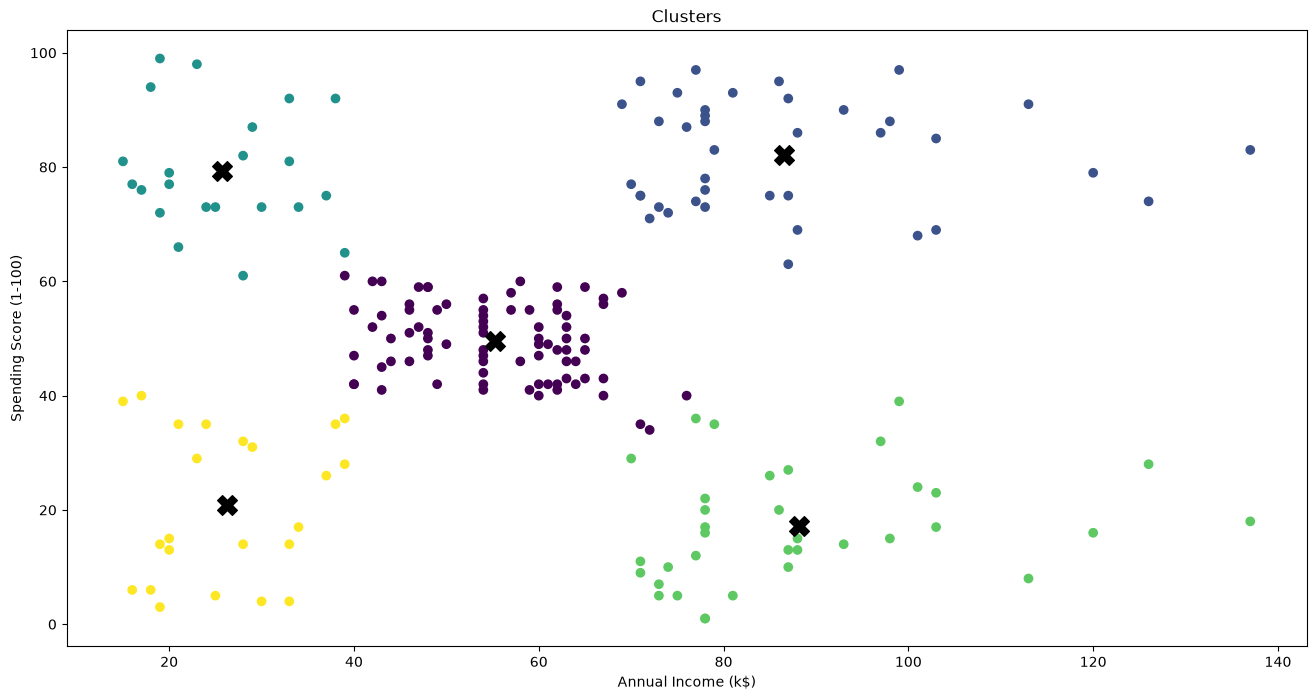

In [4]:
import matplotlib.pyplot as plt

kmeans = pipeline.named_steps['kmeans']
cluster_centres = kmeans.cluster_centers_
centers = scaler.inverse_transform(cluster_centres)
print(centers)


plt.figure(figsize=(16,8))
plt.title('Clusters')
plt.scatter(x['Annual Income (k$)'], x['Spending Score (1-100)'], c=df['KMeans Cluster'], cmap='viridis')
plt.scatter(centers[:,0], centers[:,1], c='black', marker='X', s=200)
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.show()


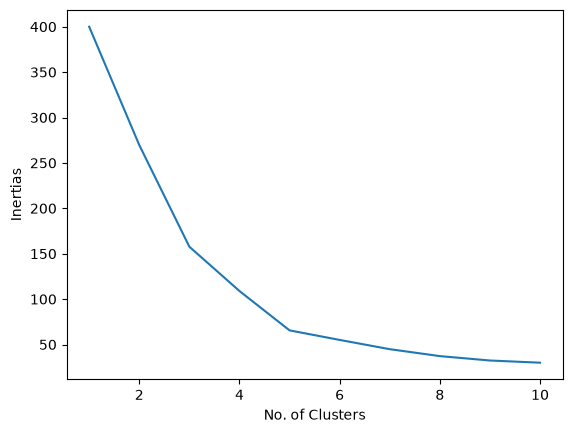

In [5]:
intertias = []

for k in range(1,11):
    pipeline = make_pipeline(StandardScaler(),KMeans(n_clusters=k, n_init=10, random_state=42))
    pipeline.fit(x)
    kmeans = pipeline.named_steps['kmeans']
    intertias.append(kmeans.inertia_)

plt.plot(range(1,11), intertias)
plt.xlabel('No. of Clusters')
plt.ylabel('Inertias')
plt.show()

## K-Medoids

In [6]:
from sklearn_extra.cluster import KMedoids

In [10]:
#taking the same dataset and value of x (Annual Income & Spending Score)
#not making a pipeline this time - forgot why so search it up

scaler=StandardScaler()
x_scaled = scaler.fit_transform(x)
kmodel = KMedoids(n_clusters=5, metric='euclidean', init='heuristic', max_iter=300, random_state=42)
kmodel.fit(x_scaled)
df['KMedoids Cluster'] = kmodel.labels_
df

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100),KMeans Cluster,KMedoids Cluster
0,1,Male,19,15,39,4,1
1,2,Male,21,15,81,2,0
2,3,Female,20,16,6,4,1
3,4,Female,23,16,77,2,0
4,5,Female,31,17,40,4,1
...,...,...,...,...,...,...,...
195,196,Female,35,120,79,1,3
196,197,Female,45,126,28,3,4
197,198,Male,32,126,74,1,3
198,199,Male,32,137,18,3,4


The difference between K-Means and K-Medoids is that in K-Medoids, the centroid will always be a datapoint from the dataset, whereas in K-means, the centroid may or may not be an actual datapoint

And why is that? because in K-Means we calculate the centroid based on the mean of the values assigned to that cluster. In K-Medoids it tries to minimise the sum of distances between points and their assigned medoids. When the sum is at its lowest, it converges and keeps those points as the medoids

In [12]:
cluster_centres = kmodel.cluster_centers_
centers = scaler.inverse_transform(cluster_centres)

import numpy as np

# centers[:,0] in x['Annual Income (k$)']
# print(centers[:,0])
# type(x['Annual Income (k$)'])

matches = np.isin(centers[:,0], x['Annual Income (k$)'])
matches.all()

np.True_

Yes, the above code proves that all the centroids (aka medoids) of the clusters are actual datapoints in the dataset.

## Fuzzy C-Means

In [13]:
import skfuzzy as fuzz
import os
os.environ['OMP_NUM_THREADS'] = '1'

In [14]:
#taking the same file and columns
x = df[['Annual Income (k$)', 'Spending Score (1-100)']]
x = x.T
result = fuzz.cluster.cmeans(x,c=5,m=2,error=0.005,maxiter=1000)
centers = result[0]
u = result[1]
membership_df = pd.DataFrame(u.T, columns=[f'Cluster {i}' for i in range(u.shape[0])])
membership_df

,Cluster 0,Cluster 1,Cluster 2,Cluster 3,Cluster 4
0,0.186068,0.545082,0.055019,0.045380,0.168451
1,0.883444,0.030859,0.013555,0.025831,0.046311
2,0.043928,0.822287,0.046039,0.021914,0.065832
3,0.897827,0.027996,0.011560,0.020964,0.041653
4,0.192719,0.526163,0.055207,0.046073,0.179838
...,...,...,...,...,...
195,0.082881,0.059059,0.144402,0.566478,0.147181
196,0.069325,0.087018,0.500687,0.181718,0.161252
197,0.089906,0.069411,0.183284,0.493986,0.163413
198,0.078218,0.102286,0.477417,0.177607,0.164473


In this algorithm, data points may belong to other clusters. Above is the probability of a datapoint belonging to a specific cluster

In [18]:
fcm_labels = np.argmax(u,axis=0)
df['FCM Cluster'] = fcm_labels
df

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100),KMeans Cluster,KMedoids Cluster,FCM Cluster
0,1,Male,19,15,39,4,1,1
1,2,Male,21,15,81,2,0,0
2,3,Female,20,16,6,4,1,1
3,4,Female,23,16,77,2,0,0
4,5,Female,31,17,40,4,1,1
...,...,...,...,...,...,...,...,...
195,196,Female,35,120,79,1,3,3
196,197,Female,45,126,28,3,4,2
197,198,Male,32,126,74,1,3,3
198,199,Male,32,137,18,3,4,2


In [24]:
x = x.T

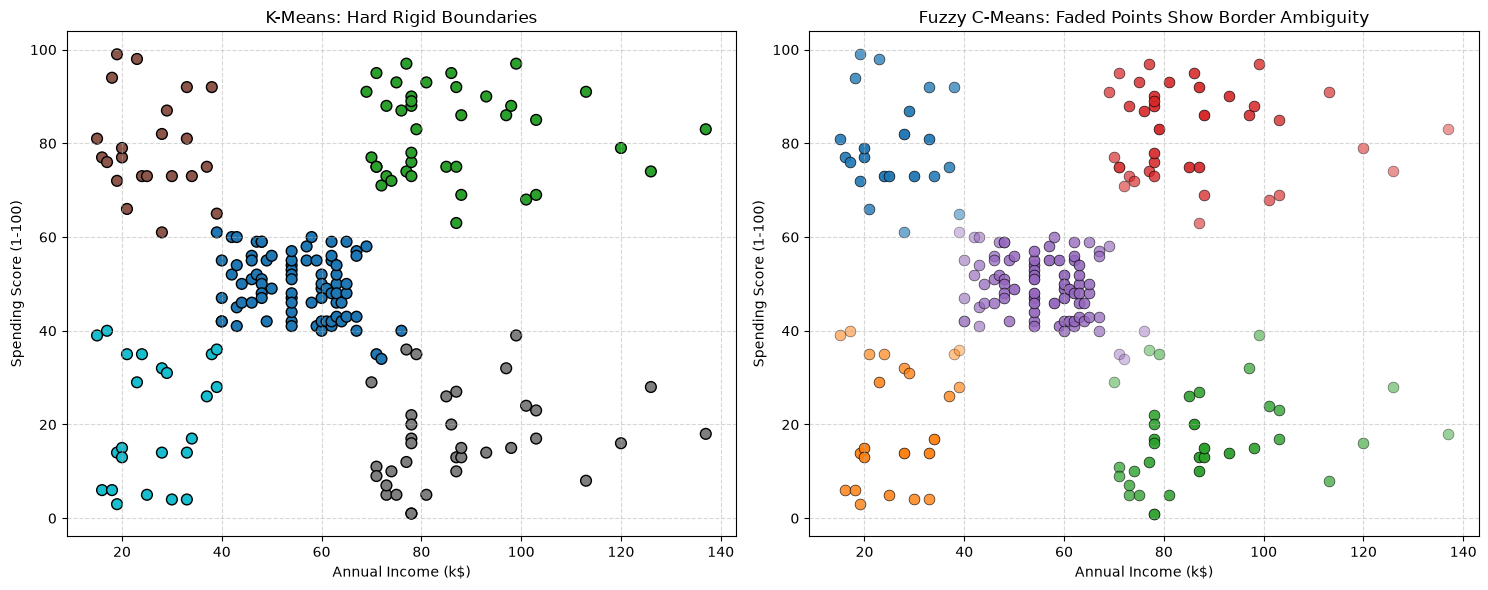

In [ ]:
fcm_labels = np.argmax(u, axis=0) 
fcm_certainty = np.max(u, axis=0) # Highest probability score for each point


fig, [ax1, ax2] = plt.subplots(1, 2, figsize=(15, 6))
cmap = plt.get_cmap('tab10')


ax1.scatter(
    x['Annual Income (k$)'], 
    x['Spending Score (1-100)'], 
    c=df['KMeans Cluster'], 
    cmap=cmap, 
    edgecolor='k', 
    s=60
)
ax1.set_title('K-Means: Hard Rigid Boundaries')
ax1.set_xlabel('Annual Income (k$)')
ax1.set_ylabel('Spending Score (1-100)')
ax1.grid(True, linestyle='--', alpha=0.5)

for i in range(len(x)):
    ax2.scatter(
        x.iloc[i, 0],  
        x.iloc[i, 1],  
        color=cmap(fcm_labels[i] % 10), 
        alpha=float(fcm_certainty[i]),   
        edgecolor='k', 
        linewidth=0.5,
        s=60
    )

ax2.set_title('Fuzzy C-Means: Faded Points Show Border Ambiguity')
ax2.set_xlabel('Annual Income (k$)')
ax2.set_ylabel('Spending Score (1-100)')
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

Used AI to visualize the difference between K-Means and Fuzzy C